# 실시간 특징 생성과 이벤트 단위 데이터 분할

목표는 결함을 가능한 빨리 탐지하고 결함 유형을 분류할 수 있는 모델링 데이터를 만드는 것입니다.

정답 레이블은 다음과 같이 명확히 분리합니다.

- `fault_type`: 0=정상, 1~4=결함 유형인 **다중 클래스 정답 레이블**
- `is_fault`: `fault_type != 0`에서 파생한 **이진 탐지 정답 레이블**

`fault_type`, `is_fault`, `efficiency_loss_pct`, `time_to_fault_min`은 입력 특징에 포함하지 않습니다. 모든 이동 특징은 현재와 과거 값만 사용합니다.


## 0. 데이터 로드와 특징 구성

특징은 실시간 계산 비용과 해석 가능성을 고려해 다음 범위로 제한합니다.

- 현재 센서값 12개와 설정값 2개
- 1·5·15·30·60분 변화량
- 5·15·60분 이동평균과 이동표준편차
- 온도·압력 설정값 편차, 냉각수/원료 유량 비율, 전력/전류 비율
- 운전 조건과 원래 결측 센서 수


In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore',category=FutureWarning)
warnings.filterwarnings('ignore',message='FigureCanvasAgg is non-interactive.*')
pd.set_option('display.max_columns',50); pd.set_option('display.width',190); pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
plt.style.use('seaborn-v0_8-whitegrid'); plt.rcParams.update({'font.family':'Nanum Gothic','axes.unicode_minus':False,'font.size':9})

DATA_PATH=Path('data/processed/chemical_process_timeseries_realtime_ffill.csv.gz')
if not DATA_PATH.exists(): DATA_PATH=Path('../data/processed/chemical_process_timeseries_realtime_ffill.csv.gz')
OUTPUT_DIR=Path('data/modeling') if Path('data').exists() else Path('../data/modeling')

core_sensors=['reactor_temp','reactor_pressure','feed_flow_rate','coolant_flow_rate','agitator_speed_rpm','reaction_rate','conversion_rate','selectivity','yield_pct','vibration_rms','motor_current','power_consumption_kw']
setpoint_cols=['temp_setpoint','pressure_setpoint']
missing_flag_cols=[f'{c}__was_missing' for c in [
 'ambient_temp_effect','reactor_temp','reactor_pressure','feed_flow_rate','coolant_flow_rate','agitator_speed_rpm','reaction_rate','conversion_rate','selectivity','yield_pct','vibration_rms','motor_current','power_consumption_kw','temp_setpoint','pressure_setpoint']]
use_cols=['timestamp','operating_regime','reactor_id','fault_type']+core_sensors+setpoint_cols+missing_flag_cols
df=pd.read_csv(DATA_PATH,usecols=use_cols,parse_dates=['timestamp']).sort_values(['reactor_id','timestamp']).reset_index(drop=True)
df['row_id']=np.arange(len(df),dtype=np.int64)
print(f'원본: {len(df):,}행 × {df.shape[1]}열')
print('정답 레이블:',df['fault_type'].value_counts().sort_index().to_dict())


원본: 777,600행 × 34열
정답 레이블: {0: 749699, 1: 9143, 2: 6842, 3: 4474, 4: 7442}


## 1. 결함 이벤트 식별과 분할

각 결함 유형 안에서 이벤트 시작 시각 순으로 정렬합니다.

- 마지막 2개 이벤트: test
- 그 앞 2개 이벤트: validation
- 나머지 이벤트: train

이 방식은 미래 이벤트를 평가에 남기면서 모든 split에 네 결함 유형을 포함합니다. 행을 무작위로 나누지 않으므로 동일 이벤트의 앞·뒤 구간이 다른 split에 섞이지 않습니다.


분할별 결함 이벤트 수
            F1  F2  F3  F4  total
split                            
train        6   5   3   5     19
validation   2   2   2   2      8
test         2   2   2   2      8

이벤트 배정
 event_id reactor_id               start  fault_type  duration_min      split
        1       B_R1 2024-01-01 05:19:00           1           691      train
        2       A_R1 2024-01-03 00:20:00           2           879      train
        3       A_R3 2024-01-05 06:12:00           4           863      train
        4       B_R3 2024-01-05 19:59:00           3           649      train
        5       B_R1 2024-01-07 20:06:00           2           202      train
        6       B_R3 2024-01-07 20:41:00           3          1301      train
        7       B_R1 2024-01-08 00:22:00           1           771      train
        8       A_R1 2024-01-14 14:06:00           2          1225      train
        9       B_R1 2024-01-14 19:58:00           1          1310      train
       10       A_R3 2024-01-

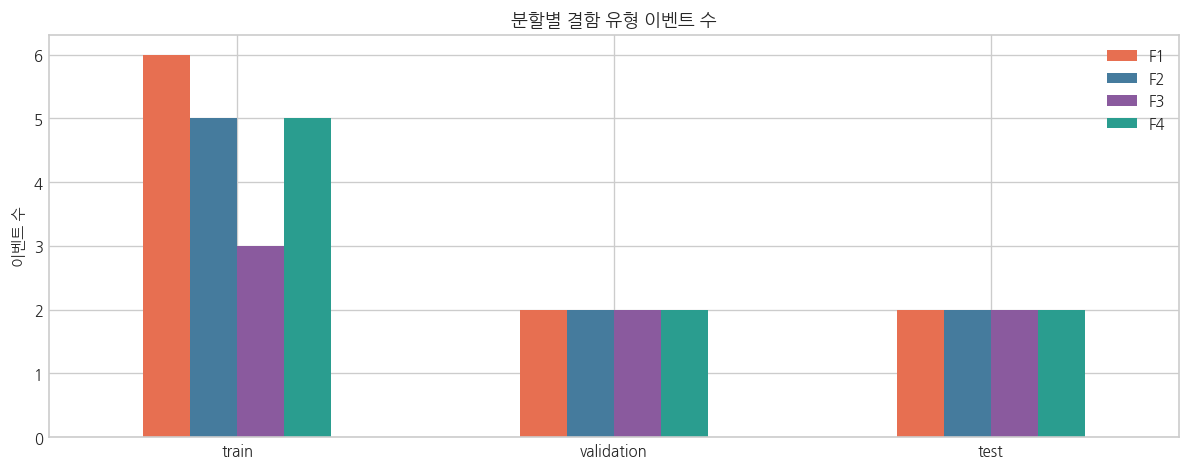

In [2]:
df['segment_start']=df.groupby('reactor_id')['fault_type'].transform(lambda s:s.ne(s.shift()))
df['segment_id']=df.groupby('reactor_id')['segment_start'].cumsum()
segments=(df.groupby(['reactor_id','segment_id'],as_index=False).agg(start=('timestamp','min'),end=('timestamp','max'),fault_type=('fault_type','first'),duration_min=('timestamp','size')))
events=segments[segments['fault_type'].ne(0)].copy().sort_values('start').reset_index(drop=True); events['event_id']=np.arange(1,len(events)+1)

events['split']='train'
for fault_type,idx in events.groupby('fault_type').groups.items():
    ordered=events.loc[idx].sort_values('start').index
    events.loc[ordered[-2:],'split']='test'
    events.loc[ordered[-4:-2],'split']='validation'

split_event_table=pd.crosstab(events['split'],events['fault_type']).reindex(['train','validation','test'])
split_event_table.columns=[f'F{c}' for c in split_event_table.columns]
split_event_table['total']=split_event_table.sum(axis=1)
print('분할별 결함 이벤트 수')
print(split_event_table.to_string())
print('\n이벤트 배정')
print(events[['event_id','reactor_id','start','fault_type','duration_min','split']].to_string(index=False))

fig,ax=plt.subplots(figsize=(10,4)); split_event_table.drop(columns='total').plot(kind='bar',ax=ax,color=['#e76f51','#457b9d','#8a5a9e','#2a9d8f'])
ax.set_title('분할별 결함 유형 이벤트 수'); ax.set_xlabel(''); ax.set_ylabel('이벤트 수'); ax.tick_params(axis='x',rotation=0); plt.tight_layout(); plt.show()


## 2. 인과적 실시간 특징 생성

`shift(k)`는 k분 전 값만 사용합니다. `rolling(window)`은 현재 시점과 그 이전 관측만 포함합니다. 반응기 경계를 넘어서 특징이 계산되지 않도록 모든 연산을 `reactor_id`별로 수행합니다.


In [3]:
feature_df=df[['row_id','timestamp','operating_regime','reactor_id','fault_type']+core_sensors+setpoint_cols].copy()
feature_df['is_fault']=feature_df['fault_type'].ne(0).astype('int8')
feature_df['regime_B']=feature_df['operating_regime'].eq('B').astype('int8')
feature_df['missing_sensor_count']=df[missing_flag_cols].sum(axis=1).astype('int8')

grouped=df.groupby('reactor_id',sort=False)
for lag in [1,5,15,30,60]:
    lagged=grouped[core_sensors].shift(lag)
    delta=(df[core_sensors]-lagged).astype('float32')
    delta.columns=[f'{c}__delta_{lag}m' for c in core_sensors]
    feature_df=pd.concat([feature_df,delta],axis=1)

for window in [5,15,60]:
    roll_mean=(grouped[core_sensors].rolling(window,min_periods=1).mean().reset_index(level=0,drop=True).astype('float32'))
    roll_std=(grouped[core_sensors].rolling(window,min_periods=max(2,window//2)).std().reset_index(level=0,drop=True).astype('float32'))
    roll_mean.columns=[f'{c}__mean_{window}m' for c in core_sensors]
    roll_std.columns=[f'{c}__std_{window}m' for c in core_sensors]
    feature_df=pd.concat([feature_df,roll_mean,roll_std],axis=1)

feature_df['temp_setpoint_error']=(feature_df['reactor_temp']-feature_df['temp_setpoint']).astype('float32')
feature_df['pressure_setpoint_error']=(feature_df['reactor_pressure']-feature_df['pressure_setpoint']).astype('float32')
feature_df['coolant_feed_ratio']=(feature_df['coolant_flow_rate']/feature_df['feed_flow_rate'].replace(0,np.nan)).astype('float32')
feature_df['power_current_ratio']=(feature_df['power_consumption_kw']/feature_df['motor_current'].replace(0,np.nan)).astype('float32')

metadata_cols=['row_id','timestamp','operating_regime','reactor_id']
target_cols=['fault_type','is_fault']
feature_cols=[c for c in feature_df.columns if c not in metadata_cols+target_cols]
leakage_cols={'fault_type','is_fault','efficiency_loss_pct','time_to_fault_min'}
assert leakage_cols.isdisjoint(feature_cols)
print(f'생성 특징 수: {len(feature_cols)}개')
print(f'정답: {target_cols}')
print(f'특징에 정답성 컬럼 포함 여부: {not leakage_cols.isdisjoint(feature_cols)}')
print(f'초기 이동통계로 생긴 결측 셀: {int(feature_df[feature_cols].isna().sum().sum()):,}')


생성 특징 수: 152개
정답: ['fault_type', 'is_fault']
특징에 정답성 컬럼 포함 여부: False
초기 이동통계로 생긴 결측 셀: 10,609


## 3. 이벤트 중심 모델링 표본 구성

각 결함 이벤트마다 다음 구간을 선택합니다.

- 시작 전 24시간의 정상 행
- 결함 시작 후 최대 6시간의 해당 결함 행

두 이벤트의 사전 정상 구간이 겹칠 수 있으므로 동일 원본 행이 여러 split에 배정되는 경우 그 행을 제외합니다. 동일 split 안의 중복은 한 번만 사용합니다.


서로 다른 split에 걸친 중복 원본 행 제외: 0개
최종 모델링 행: 59,991개

split별 행과 레이블 분포
            class_0  class_1  class_2  class_3  class_4  total
split                                                         
train         24853     2160     1642     1080     1800  31535
validation    11520      720      564      720      685  14209
test          11520      668      720      619      720  14247

특징 결측 셀: 0
원본 row_id 중복: 0


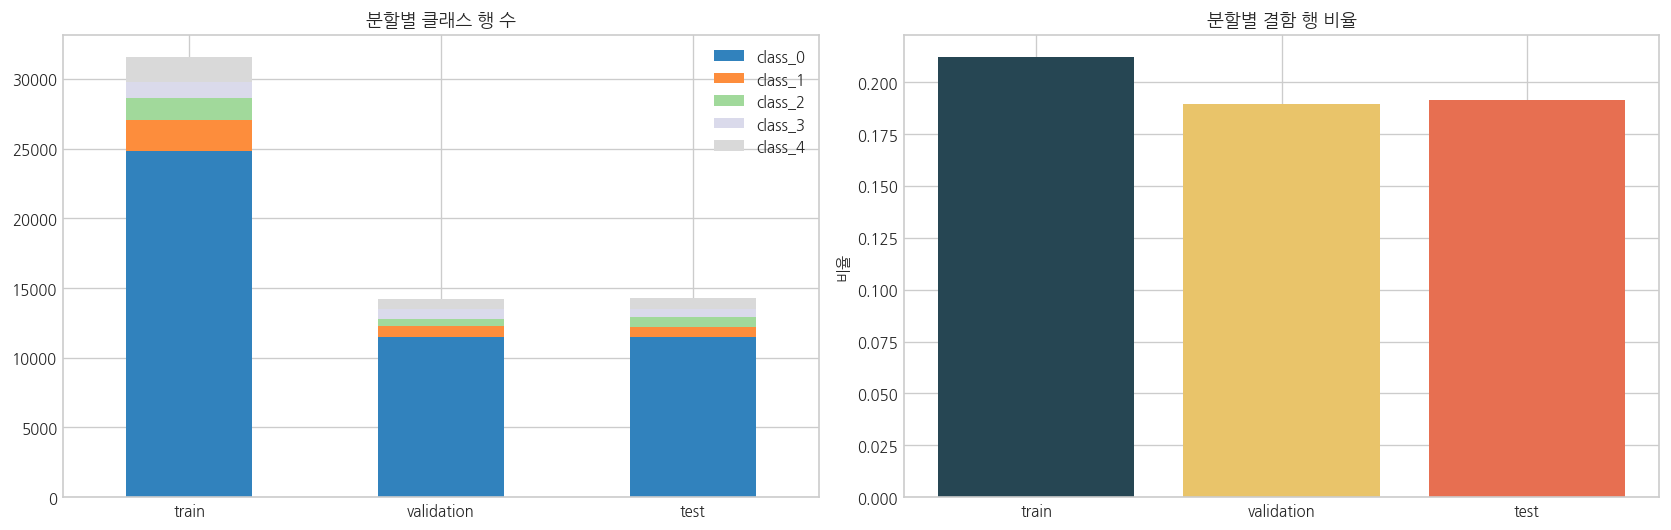

In [4]:
assignments=[]
for e in events.itertuples():
    pre=df[df['reactor_id'].eq(e.reactor_id)&df['timestamp'].ge(e.start-pd.Timedelta(hours=24))&df['timestamp'].lt(e.start)&df['fault_type'].eq(0)][['row_id','timestamp']].copy()
    post=df[df['reactor_id'].eq(e.reactor_id)&df['timestamp'].ge(e.start)&df['timestamp'].lt(e.start+pd.Timedelta(hours=6))&df['fault_type'].eq(e.fault_type)][['row_id','timestamp']].copy()
    for part,kind in [(pre,'pre_normal'),(post,'post_fault')]:
        part['sample_event_id']=e.event_id; part['split']=e.split; part['sample_kind']=kind
        part['relative_min']=((part['timestamp']-e.start).dt.total_seconds()/60).astype(int); assignments.append(part.drop(columns='timestamp'))
assignment=pd.concat(assignments,ignore_index=True)

split_count_per_row=assignment.groupby('row_id')['split'].nunique()
ambiguous_rows=split_count_per_row[split_count_per_row.gt(1)].index
assignment=assignment[~assignment['row_id'].isin(ambiguous_rows)].sort_values(['row_id','sample_event_id']).drop_duplicates('row_id')

model_data=assignment.merge(feature_df,on='row_id',how='left',validate='one_to_one')

# 반응기 시작부의 이동 특징 결측은 split별로 계산하지 않고 train 중앙값으로만 대체합니다.
train_medians=model_data.loc[model_data['split'].eq('train'),feature_cols].median(numeric_only=True)
model_data[feature_cols]=model_data[feature_cols].fillna(train_medians)

print(f'서로 다른 split에 걸친 중복 원본 행 제외: {len(ambiguous_rows):,}개')
print(f'최종 모델링 행: {len(model_data):,}개')
print('\nsplit별 행과 레이블 분포')
split_rows=model_data.groupby(['split','fault_type']).size().unstack(fill_value=0).reindex(['train','validation','test'])
split_rows.columns=[f'class_{c}' for c in split_rows.columns]; split_rows['total']=split_rows.sum(axis=1)
print(split_rows.to_string())
print(f'\n특징 결측 셀: {int(model_data[feature_cols].isna().sum().sum()):,}')
print(f'원본 row_id 중복: {int(model_data["row_id"].duplicated().sum()):,}')

fig,axes=plt.subplots(1,2,figsize=(14,4.5))
split_rows.drop(columns='total').plot(kind='bar',stacked=True,ax=axes[0],colormap='tab20c'); axes[0].set_title('분할별 클래스 행 수'); axes[0].tick_params(axis='x',rotation=0); axes[0].set_xlabel('')
ratio=model_data.groupby('split')['is_fault'].mean().reindex(['train','validation','test']); axes[1].bar(ratio.index,ratio.values,color=['#264653','#e9c46a','#e76f51']); axes[1].set_title('분할별 결함 행 비율'); axes[1].set_ylabel('비율')
plt.tight_layout(); plt.show()


## 4. 분할 누출 검증

동일 이벤트와 동일 원본 행이 여러 split에 나타나지 않는지 검사합니다. 특징 계산은 전체 시간축에서 수행했지만 모든 연산이 과거 방향이므로 미래 값이 특징에 들어가지는 않습니다. 스케일러나 모델 파라미터는 이후 train에서만 학습해야 합니다.


In [5]:
event_split_check=model_data[model_data['sample_kind'].eq('post_fault')].groupby('sample_event_id')['split'].nunique()
row_split_check=model_data.groupby('row_id')['split'].nunique()
checks={
 '모든 결함 이벤트가 한 split에만 존재': bool(event_split_check.le(1).all()),
 '모든 원본 행이 한 split에만 존재': bool(row_split_check.le(1).all()),
 'fault_type이 특징에서 제외됨': 'fault_type' not in feature_cols,
 'is_fault가 특징에서 제외됨': 'is_fault' not in feature_cols,
 'time_to_fault_min이 특징에서 제외됨': 'time_to_fault_min' not in feature_cols,
 'efficiency_loss_pct가 특징에서 제외됨': 'efficiency_loss_pct' not in feature_cols,
 '특징 결측 없음': not model_data[feature_cols].isna().any().any(),
}
print(pd.Series(checks,name='통과 여부').to_string())
assert all(checks.values())

manifest=model_data[['row_id','timestamp','reactor_id','sample_event_id','relative_min','sample_kind','split','fault_type','is_fault']].copy()
print('\n모델 입력 예시 특징')
print(pd.Series(feature_cols[:30]).to_string(index=False))


모든 결함 이벤트가 한 split에만 존재          True
모든 원본 행이 한 split에만 존재            True
fault_type이 특징에서 제외됨             True
is_fault가 특징에서 제외됨               True
time_to_fault_min이 특징에서 제외됨      True
efficiency_loss_pct가 특징에서 제외됨    True
특징 결측 없음                         True

모델 입력 예시 특징
                  reactor_temp
              reactor_pressure
                feed_flow_rate
             coolant_flow_rate
            agitator_speed_rpm
                 reaction_rate
               conversion_rate
                   selectivity
                     yield_pct
                 vibration_rms
                 motor_current
          power_consumption_kw
                 temp_setpoint
             pressure_setpoint
                      regime_B
          missing_sensor_count
        reactor_temp__delta_1m
    reactor_pressure__delta_1m
      feed_flow_rate__delta_1m
   coolant_flow_rate__delta_1m
  agitator_speed_rpm__delta_1m
       reaction_rate__delta_1m
     conversion_rate__delta_1m
        

## 5. 산출물 저장

모델링 데이터에는 메타데이터, 정답, 특징이 함께 저장됩니다. 학습 시 `feature_schema.json`의 `feature_columns`만 입력 X로 사용하고 `fault_type` 또는 `is_fault`를 y로 선택합니다.


In [6]:
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
data_path=OUTPUT_DIR/'realtime_event_features.csv.gz'
manifest_path=OUTPUT_DIR/'event_split_manifest.csv'
schema_path=OUTPUT_DIR/'feature_schema.json'

model_data.to_csv(data_path,index=False,compression='gzip')
manifest.to_csv(manifest_path,index=False)
schema={
 'feature_columns':feature_cols,
 'target_columns':target_cols,
 'metadata_columns':['row_id','timestamp','reactor_id','operating_regime','sample_event_id','relative_min','sample_kind','split'],
 'excluded_leakage_columns':['fault_type','is_fault','efficiency_loss_pct','time_to_fault_min'],
 'causal_features_only':True,
 'split_policy':'Within each fault type, chronological: last 2 events=test, previous 2=validation, remaining=train',
 'sample_policy':'24h pre-event normal + up to 6h active fault per event',
 'train_median_imputation':{k:float(v) for k,v in train_medians.items()},
}
schema_path.write_text(json.dumps(schema,ensure_ascii=False,indent=2),encoding='utf-8')

print(f'특징 데이터: {data_path} ({data_path.stat().st_size/1024**2:.1f} MB)')
print(f'분할 manifest: {manifest_path} ({manifest_path.stat().st_size/1024**2:.1f} MB)')
print(f'특징 schema: {schema_path}')


특징 데이터: data/modeling/realtime_event_features.csv.gz (42.7 MB)
분할 manifest: data/modeling/event_split_manifest.csv (3.5 MB)
특징 schema: data/modeling/feature_schema.json


## 6. 결론과 사용 방법

- `fault_type`은 0~4의 정답 레이블로 보존됐으며 특징에서 제외했습니다.
- `is_fault`는 1단계 정상/결함 탐지용 파생 정답입니다.
- 특징은 모두 현재 또는 과거 관측으로 계산했습니다.
- 35개 결함 이벤트를 train 19개, validation 8개, test 8개로 분리했고 모든 split에 F1~F4가 존재합니다.
- 각 이벤트의 사전 정상 24시간과 발생 후 최대 6시간을 같은 split에 묶었습니다.
- 남은 특징 결측은 train 중앙값으로만 처리했습니다.

권장 모델링 순서는 다음과 같습니다.

1. `is_fault`로 이진 탐지 모델 학습
2. 결함으로 탐지된 행에서 `fault_type` 1~4 분류 모델 학습
3. validation에서 임계값과 연속 경보 조건 결정
4. test에서 이벤트 탐지율, 오탐, 탐지 지연시간, 유형별 재현율 평가

이벤트 주변 표본을 사용했기 때문에 첫 모델 비교에는 적합하지만, 실제 운영 오탐률은 이후 전체 연속 test 기간에서도 추가 평가해야 합니다.
